In [290]:
import torch
from torch import nn # nural network
import matplotlib.pyplot as plt

torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 3050 6GB Laptop GPU'

In [291]:
# Synthetic Data generation
import numpy as np

weight = 10
bias = 10

# Number config
start = 0
end = 50
step = 0.2

X = torch.arange(start, end, step).unsqueeze(dim=1)

# random vector generation with targeted ranging
bias_listing = torch.tensor(np.random.randint(bias*(-1),bias, X.shape))

y = weight*X + bias_listing

X.shape, y.shape

(torch.Size([250, 1]), torch.Size([250, 1]))

In [292]:
# Test and training split
'''
we also have to make this test training spliting a more robust into yantragya
with having that batch samlping ways to craft good training and testing elements

we can fetch with making np based sampling through the given indexing
'''
split_ratio = 80 # 80/20 split
spliting_index = int((80*len(X))/100)

X_train = X[:spliting_index]
y_train = y[:spliting_index]

X_test = X[spliting_index:]
y_test = y[spliting_index:]

X_train.shape, y_train.shape

(torch.Size([200, 1]), torch.Size([200, 1]))

In [293]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

'''
TensorDataset
wrap tensor for them to work as datast

Loader
Makes them iteratable along with batches configurations

Streamlines to manage tensors, 
and makes us to simple iterate our dataset to fetch the elemnts for making things work

** Read the docs remaining **
'''

# config load for model
BATCH_SIZE = 10
NUM_WORKER = 0

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKER)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKER)

len(train_dataloader) # total batch count

20

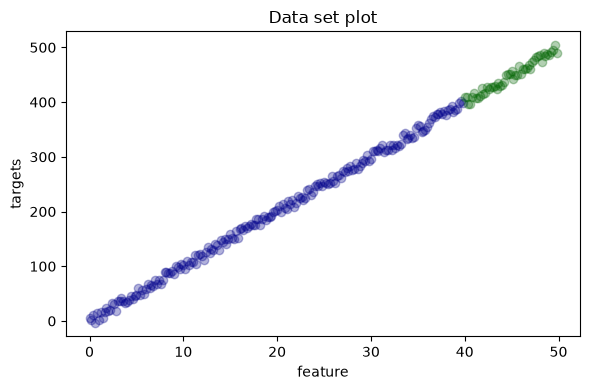

In [294]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,4), layout='tight')

ax.set(
    title="Data set plot",
    xlabel="feature",
    ylabel="targets"
)
ax.scatter(X_train, y_train, alpha=0.3, color="darkblue")
ax.scatter(X_test, y_test, color="darkgreen", alpha=0.3)

## Model Definition
``` torch.nn dependency ``` required for defining new models with torch | custom craft
Core base class framework to use for model definition
facilities parameter managements and other required elements

* Need to read its documentation for more details

In [295]:
import torch
from torch import nn 

class LinearRegression(nn.Module):
    '''
    Linear Regression model
    Input : One feature per sample
    Output : One value per feature input

    foundational setup for building models
    with just simple random functions
    '''
    def __init__(self):
        super().__init__()
        # Initiating Random parameters for the model to optimize with | requires_grad -> Auto gradiation ⚙️
        self.weights = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
        self.bias = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)

    def forward(self, x:torch.Tensor)->torch.Tensor:
        return self.weights*x + self.bias

# Loss Functions

Specific loss function plays role into convergence of the model at very much extent, we need to be sure with dataset which we using to choose for the respective loss function to use with,

**MeanAbsoluteError**

works well with clean dataset and to get convergence quick, struggle with outlier containing dataset

**HuberLosss Functioon**

Works good with outliers differentiation easy at near optimals due to squared values with delata config


In [296]:
# Error Definition

class MeanAbsoluteError(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self,predictions:torch.Tensor, targets:torch.Tensor)->torch.Tensor:
        """
        Computes Mean Absolute Error between predictions and targets

        Parameters 
        predictions : Model prediction numbers
        targets : Target values
        """
        absolute_errors = torch.abs(predictions - targets) # Absolute Error
        return torch.mean(absolute_errors)  # Prediction Loss
        
class HuberLossError(nn.Module):
    def __init__(self, delta:float=1.0):
        super().__init__()
        self.delta = delta
        
    def forward(self,predictions:torch.Tensor, targets:torch.Tensor)->torch.Tensor:
        """
        - Quadratic for small loss ( smooth gradients )
        - linear for larget error (robust to outliers )
        """
        residuals = predictions - targets
        abs_residual = torch.abs(residuals)

        # Quadratic Mask
        quadratic_mask = abs_residuals <= self.delta
        linear_mask = abs_residual > self.delta

        quadratic_loss = 0.5 * residuals**2
        linear_loss = self.delta*abs_residuals - 0.5*self.delta**2

        loss = quadratic_mask * quadratic_loss + linear_mask * linear_loss
        return torch.mean(loss)

In [297]:
# Testing Loss 
custom_mae = MeanAbsoluteError()
model = LinearRegression()

predictions = model(X_train)

print(custom_mae(predictions, X_train))  # Final output

tensor(9.9202, grad_fn=<MeanBackward0>)


In [298]:
import torch

torch.manual_seed(30)

model_0 = LinearRegression()

list(model_0.parameters()) # fetches the parameters values

[Parameter containing:
 tensor([0.4705], requires_grad=True),
 Parameter containing:
 tensor([1.6563], requires_grad=True)]

In [299]:
import torch

# Prediction order with models
'''
Working with drawing inference through the model
+ Disables the autograd features to keep numbers in stable state
+ it is context manager in the sense fro infering through model
'''
with torch.inference_mode():
    predictions = model_0(X_test)

# Prediction outputs 
print(len(X_test))
print(len(predictions))

50
50


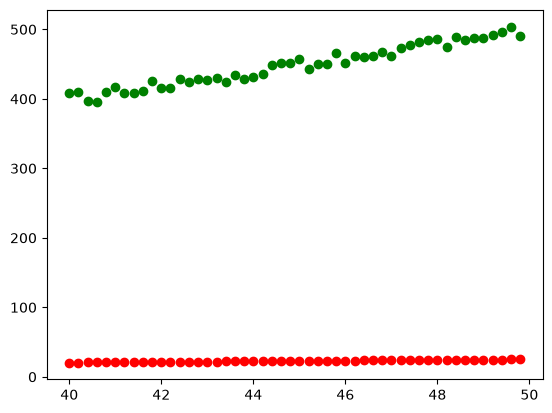

In [300]:
# ploting the predictions
import matplotlib.pyplot as plt 

# comparision with original values and original datasets

plt.scatter(X_test, y_test, color="green")
plt.scatter(X_test, predictions, color="red")

Training Needs two components
1. Loss function
2. Optimization rules

As we do with gradient descent

In [301]:
# configure the loss function

loss_function = nn.L1Loss()

optimizer = torch.optim.SGD(
    params= model_0.parameters(),
    lr=0.01
)

print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [302]:
import torch

# 1. Fixed naming typo
EPOCHS = 100
training_loss_info = []
testing_loss_info = []

'''
Need to learn a lot with Building Model
Documentation needs a deep review to learn to build model with torch
'''

for epoch in range(EPOCHS):
    ### --- TRAINING STEP --- ###
    model_0.train() # Set to training mode
    
    # 1. Forward pass
    prediction = model_0(X_train) 
    loss = loss_function(prediction, y_train) 
    
    # 2. Track training loss
    training_loss_info.append(loss.item()) 
    
    # 3. Optimizer updates
    optimizer.zero_grad() # Clear previous gradients
    loss.backward()       # Backpropagation
    optimizer.step()       # Update parameters

    ### --- TESTING STEP --- ###
    model_0.eval() # Put model in evaluation mode
    
    # Turn off gradient tracking for efficiency
    with torch.inference_mode(): 
        # 1. Forward pass on test data
        test_predictions = model_0(X_test)
        test_loss = loss_function(test_predictions, y_test)
        
        # 2. Track testing loss
        testing_loss_info.append(test_loss.item())
        
    # Optional: Print progress every 50 epochs
    if epoch % 50 == 0:
        print(f"Epoch: {epoch} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")


Epoch: 0 | Train Loss: 188.5014 | Test Loss: 416.3605
Epoch: 50 | Train Loss: 5.0100 | Test Loss: 5.0348


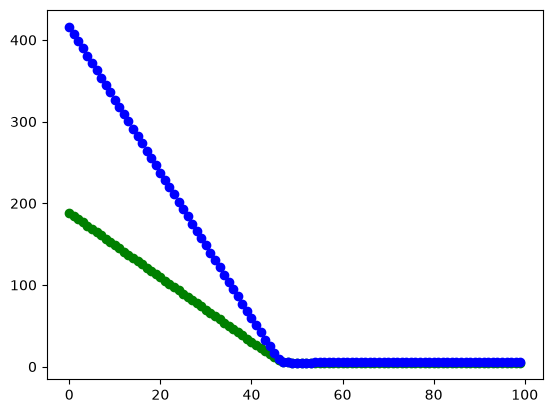

In [303]:
# Ploting trainig and testing loss graph
import matplotlib.pyplot as plt
import numpy as np

epotches = np.arange(0, EPOCHS)

plt.scatter(epotches, training_loss_info, color="green")
plt.scatter(epotches, testing_loss_info, color="blue")

50
50


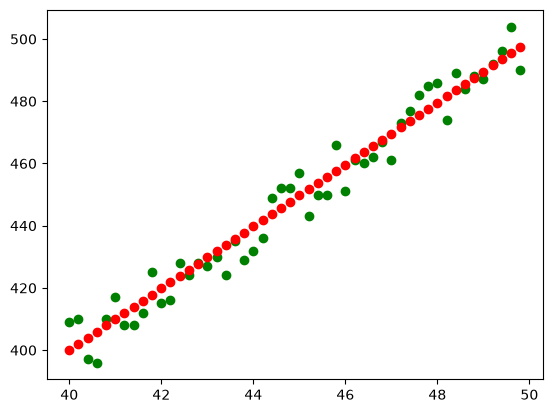

In [304]:
# ploting the predictions
import matplotlib.pyplot as plt 
import torch

# Prediction order with models
'''
Working with drawing inference through the model
+ Disables the autograd features to keep numbers in stable state
+ it is context manager in the sense fro infering through model
'''
with torch.inference_mode():
    predictions = model_0(X_test)

# Prediction outputs 
print(len(X_test))
print(len(predictions))
# comparision with original values and original datasets
'''
We can go with batch based processing for the inference
along with information fetch for the training information
'''
plt.scatter(X_test, y_test, color="green")
plt.scatter(X_test, predictions, color="red")

In [305]:
# Model Serialization Technique 
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

print(f"Model path  : {MODEL_PATH.absolute()}")

MODEL_NAME = 'pytorch_model_workflow.pth'
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# saving the model weights
'''State dict gives the weights and bias to save for the model | dict -> Bytes'''
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)



Model path  : /home/madhav/workstation/Lab/src/lab/Deep/models
